In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob
import matplotlib as mpl
from scipy.optimize import curve_fit
from scipy.ndimage import gaussian_filter1d
from scipy.spatial import distance_matrix
from scipy.stats import linregress
from hoomd_blue_test_lib.NotebookAnalysis import *
from hoomd_blue_test_lib.GSDTrajIO import LoadGSDTrajFreud
from natsort import natsorted
# from hoomd_blue_test_lib import AngleStats as ang
import gsd.hoomd
from tqdm import tqdm

#### A way to use externel fonts in matplotlib without installing it
from matplotlib import font_manager
font_dirs = ['/users/ankit.gupta/.fonts/']
font_files = font_manager.findSystemFonts(fontpaths=font_dirs)
for font_file in font_files:
    font_manager.fontManager.addfont(font_file)
#### A way to use externel fonts in matplotlib without installing it

mpl.rcParams['font.family'] = 'Nunito'
mpl.rcParams['font.size'] = 18
mpl.rcParams['axes.linewidth'] = 2
mpl.rcParams['axes.spines.top'] = False
mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['xtick.major.size'] = 10
mpl.rcParams['xtick.major.width'] = 2
mpl.rcParams['ytick.major.size'] = 10
mpl.rcParams['ytick.major.width'] = 2

/users/ankit.gupta/mambaforge/envs/hoomd_blue/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [3]:
path = get_files_list("./test4_N_1000_long_sim_gpu_gws/",check_msd_mat=False)

In [4]:
for i in list(path.keys()):
    if "num_1000_" not in i:
        del path[i]

path

{'gamma_0.1_N_num_1000_repE_10_ak_10_box_len_100_bk_1000': ['./test4_N_1000_long_sim_gpu_gws/gamma_0.1_N_num_1000_repE_10_ak_10_box_len_100_bk_1000/rep_1',
  './test4_N_1000_long_sim_gpu_gws/gamma_0.1_N_num_1000_repE_10_ak_10_box_len_100_bk_1000/rep_2',
  './test4_N_1000_long_sim_gpu_gws/gamma_0.1_N_num_1000_repE_10_ak_10_box_len_100_bk_1000/rep_3',
  './test4_N_1000_long_sim_gpu_gws/gamma_0.1_N_num_1000_repE_10_ak_10_box_len_100_bk_1000/rep_4',
  './test4_N_1000_long_sim_gpu_gws/gamma_0.1_N_num_1000_repE_10_ak_10_box_len_100_bk_1000/rep_5'],
 'gamma_0.1_N_num_1000_repE_10_ak_20_box_len_100_bk_1000': ['./test4_N_1000_long_sim_gpu_gws/gamma_0.1_N_num_1000_repE_10_ak_20_box_len_100_bk_1000/rep_1',
  './test4_N_1000_long_sim_gpu_gws/gamma_0.1_N_num_1000_repE_10_ak_20_box_len_100_bk_1000/rep_2',
  './test4_N_1000_long_sim_gpu_gws/gamma_0.1_N_num_1000_repE_10_ak_20_box_len_100_bk_1000/rep_3',
  './test4_N_1000_long_sim_gpu_gws/gamma_0.1_N_num_1000_repE_10_ak_20_box_len_100_bk_1000/rep_4',
 

Text(0, 0.5, 'kinetic temperature')

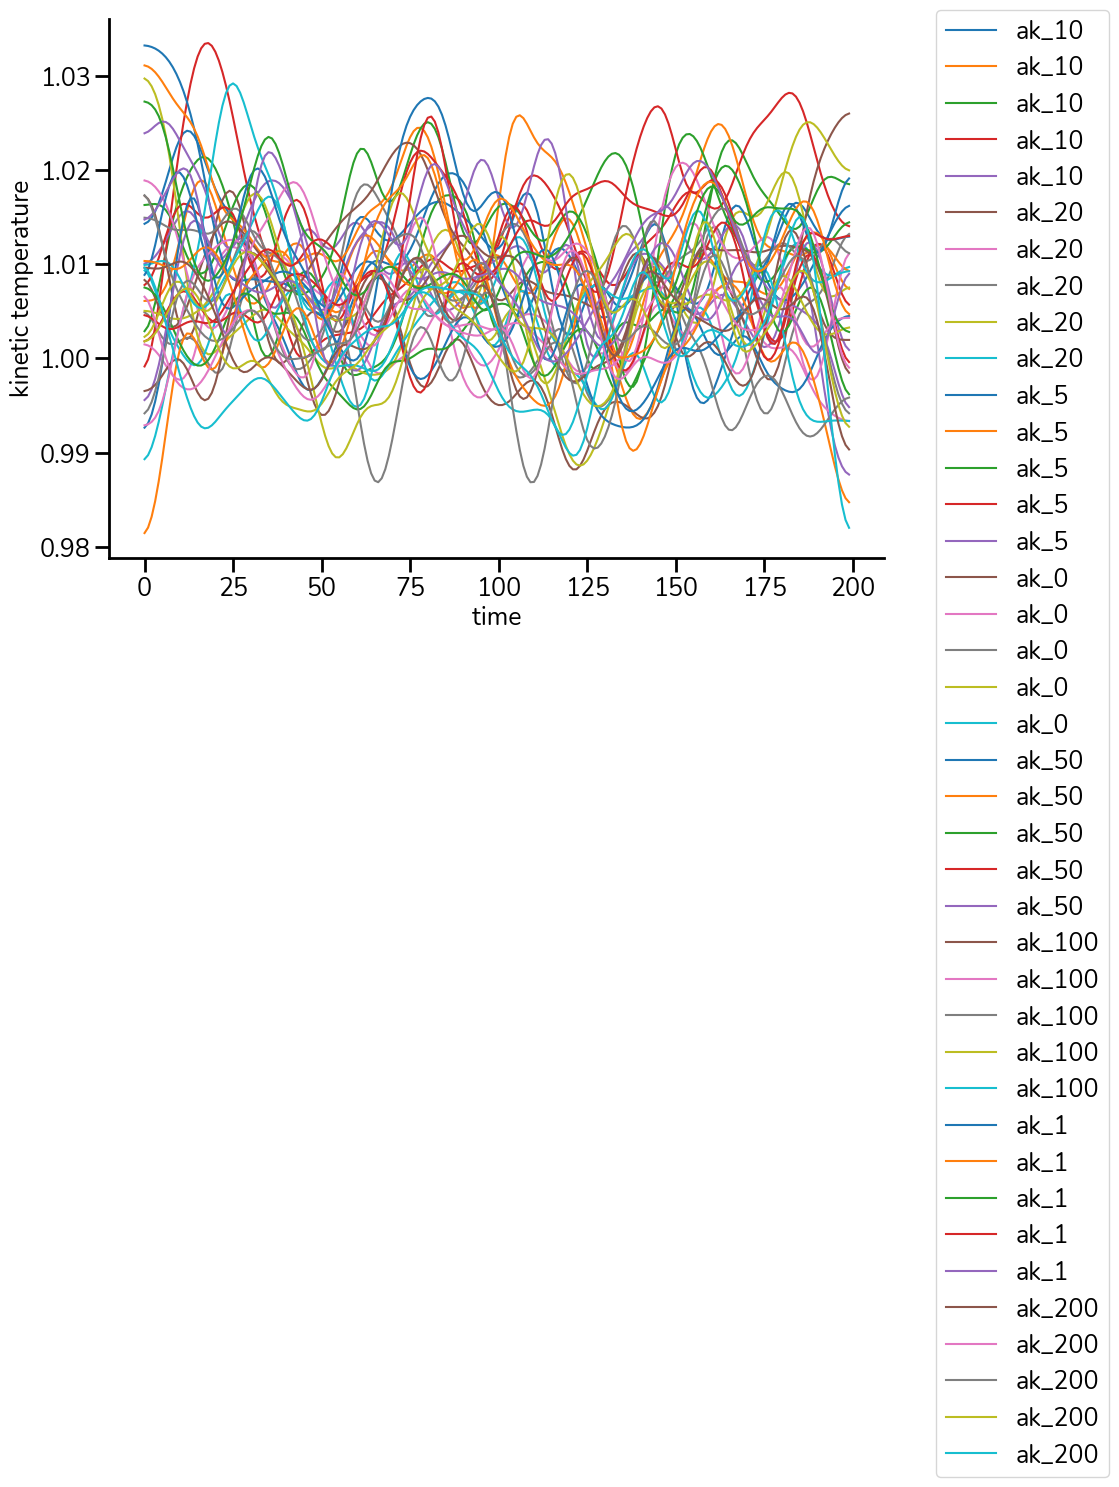

In [5]:
fig,ax = plt.subplots(figsize=(10,7))
for i in path.keys():
    for j in path[i]:
        ke = pd.read_table(j+"/trajectory.log")
        ax.plot(gaussian_filter1d(list(ke["kinetic_temperature"]),5),label=i.split("_box")[0].split("repE_10_")[1])
ax.legend(bbox_to_anchor=(1.05, 1.04))
ax.set_xlabel("time")
ax.set_ylabel("kinetic temperature")

In [6]:
def GetBondVectors(
    coordsArray
):
    """
        Get bond vectors from an array of coordinates
        
        PARAMETERS
        ----------
        coordsArray: 2D numpy array
            coordinates of the monomers
        
        OUTPUT
        ------
        2D numpy array
            coordinates of the bond vectors    
    """
    return coordsArray[1:] - coordsArray[:-1]

def GetAnglesFromBondVectors(
    bondVectors
):
    """
        Get angles from bond vectors
        
        PARAMETERS
        ----------
        bondVectors: 2D numpy array
            bond vectors of the monomers
        
        OUTPUT
        ------
        2D numpy array
            angles of the monomers    
    """
    normed_vecs = bondVectors/np.linalg.norm(bondVectors,axis=1,keepdims=True)
    cos_theta = np.dot(normed_vecs, normed_vecs.T)
    cos_theta = np.clip(cos_theta, -1.0, 1.0)
    return cos_theta

def GetAvgAngles(angle_matrix):
    avg_angles = []
    for i in range(1,angle_matrix.shape[0]):
        avg_angles.append(np.diagonal(angle_matrix,offset=i).mean())
    return np.array(avg_angles)

def GetPersistenceLength(
    avgCosθ, 
    monomerSep,
    avgBondLen=1.0
):
    """
        Estimate persistence length value by fitting a exponential curve
        Using formula:
            <cosθ> = e^-(L/p)
        where the angle θ is between a vector that is tangent to the 
        polymer at position 0 (zero) and a tangent vector at a distance 
        away from position 0, along the contour of the chain. where P is 
        the persistence length and the angled brackets denote the average 
        over all starting positions.
        
        PARAMETERS
        ----------
        avgCosθ: 1D numpy array
            average value of cosθ of bond vectors
        monomerSep: list/1D numpy array
            list of spatial distance between bond vectors whose average cosθ 
            value is provided
        
        OUTPUT
        ------
        persistence length: float
    """
    # plList = linregress(-np.log(avgCosθ), 
    #                     monomerSep)
    # plList = linregress(monomerSep, 
    #                     np.log(avgCosθ), 
    #                     )
    # return((-1/plList[0],0))
    
    cosθ = lambda x,lp: np.exp(-(x * avgBondLen)/lp)
    lp,r = curve_fit(cosθ, monomerSep, avgCosθ)
    return (lp[0],r[0])

    # damped_cosine = lambda n, A, L_p, lam, phi: A * np.exp(-n / L_p) * np.cos(2 * np.pi * n / lam + phi)
    # p0 = [1.0, 10.0, 10.0, 0.0]
    # bounds = ([0, 0, 1, -np.pi], [1.5, np.inf, np.inf, np.pi])
    # params, cov = curve_fit(damped_cosine, monomerSep, avgCosθ, p0=p0, bounds=bounds)
    # A_fit, Lp_fit, lambda_fit, phi_fit = params
    # return params

In [7]:
traj = LoadGSDTrajFreud(path["gamma_0.1_N_num_1000_repE_10_ak_10_box_len_100_bk_1000"][0]+"/trajectory.gsd")

In [8]:
traj["position"].shape

(200, 1000, 3)

In [9]:
anglesDict = {}
bondsLenDict = {}
for i in tqdm(path.keys()):
    anglesDict[i] = []
    bondsLenDict[i] = []
    for j in path[i]:
        traj = LoadGSDTrajFreud(j+"/trajectory.gsd")
        frames = np.arange(-50,0)
        for fr in frames:
            coords = traj["position"][fr]
            bondsLenDict[i].append(np.linalg.norm(coords[0:-1]-coords[1:],axis=1))
            bond_vecs = GetBondVectors(coords)
            angles_mat = GetAnglesFromBondVectors(bond_vecs)
            avg_angles = GetAvgAngles(angles_mat)
            anglesDict[i].append(avg_angles)
    anglesDict[i] = np.array(anglesDict[i])

  0%|          | 0/8 [00:00<?, ?it/s]

100%|██████████| 8/8 [00:36<00:00,  4.54s/it]


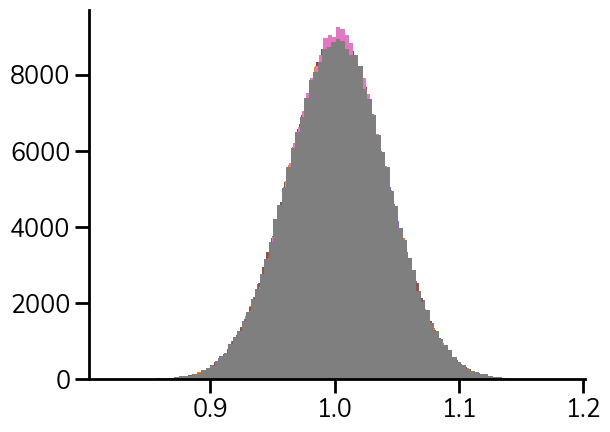

In [11]:
for i in bondsLenDict.keys():
    plt.hist(np.array(bondsLenDict[i]).flatten(),bins=100)

In [12]:
anglesDict["gamma_0.1_N_num_1000_repE_10_ak_50_box_len_100_bk_1000"]

array([[ 0.97923756,  0.96108836,  0.94280255, ..., -0.63274235,
        -0.69002473, -0.6333419 ],
       [ 0.97911584,  0.95988053,  0.9400163 , ..., -0.34189987,
        -0.35785562, -0.14908743],
       [ 0.97826946,  0.95932287,  0.9411831 , ..., -0.7442224 ,
        -0.81536233, -0.7846472 ],
       ...,
       [ 0.9793668 ,  0.9621331 ,  0.9436756 , ..., -0.18325423,
        -0.11186623,  0.06261203],
       [ 0.9794433 ,  0.96165955,  0.9445106 , ...,  0.26721206,
         0.21016091,  0.11740515],
       [ 0.9783998 ,  0.95802265,  0.9399136 , ..., -0.07982852,
         0.01931596,  0.14781883]], dtype=float32)

In [13]:
# anglesDict = {}
# for i in foldersDict.keys():
#     traj = gsd.hoomd.open(foldersDict[i])
#     snapshot = traj[-3]
#     coords = snapshot.particles.position[N-filamentLength:N,:]
#     # coords = snapshot.particles.position[N//2-filamentLength:N//2,:]
#     bvs = ang.GetBondVectors(coords)
#     bas = ang.GetAngles(bvs,bvs.T)
#     anglesDict[i] = bas

In [14]:
# anglesDict["20_50_100_10"]dd

In [11]:
avgAvgAngles = {}
for i in anglesDict.keys():
    avgAvgAngles[i] = np.mean(anglesDict[i],axis=0)
    # avgAvgAngles[i] = ang.AvgAngleValues(anglesDict[i])

In [12]:
avgAvgAngles["gamma_0.1_N_num_1000_repE_10_ak_10_box_len_100_bk_1000"].shape

(998,)

In [13]:
# fig,ax = plt.subplots(figsize=(20,10))
# for i,j in avgAvgAngles.items():
#     ax.plot(-1/np.log(ang.AvgAngleValues(j)[:100]),label=i,marker=".")
# plt.legend(bbox_to_anchor=(1.05, 1.04))

Text(0, 0.5, '$\\langle cos\\theta \\rangle$')

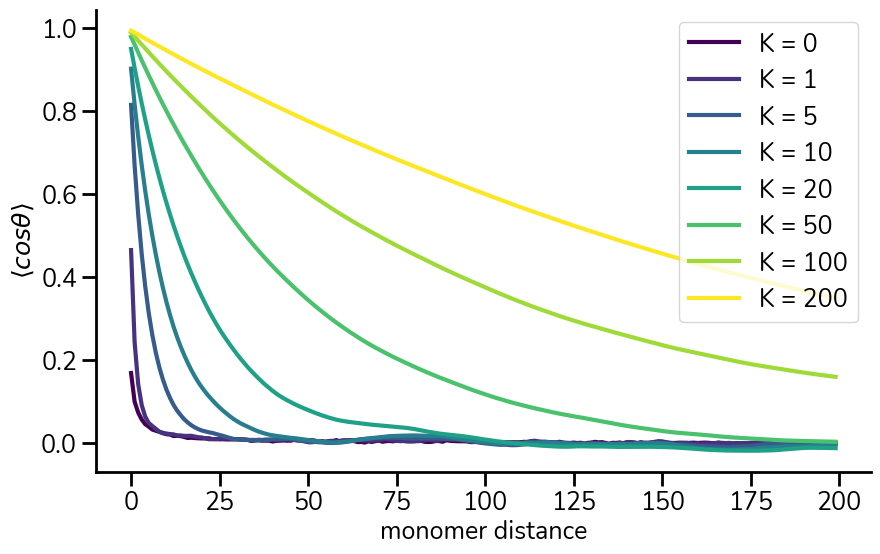

In [14]:
fig,ax = plt.subplots(figsize=(10,6))
clrs = plt.cm.viridis(np.linspace(0,1,len(anglesDict.keys())))
for ic,i in enumerate(natsorted(anglesDict.keys())):
    ax.plot(avgAvgAngles[i][:200],label="K = "+i.split("_")[8],color=clrs[ic],lw=3)
    # ax_new.plot(ang.AvgAngleValues(j)[:80])
ax.legend(loc="upper right")#bbox_to_anchor=(1.05, 1.04))
ax.set_xlabel("monomer distance")
ax.set_ylabel(r"$\langle cos\theta \rangle$")
# plt.savefig("angle_curve.jpg",dpi=100,bbox_inches="tight")

Text(0, 0.5, '$\\langle cos\\theta \\rangle$')

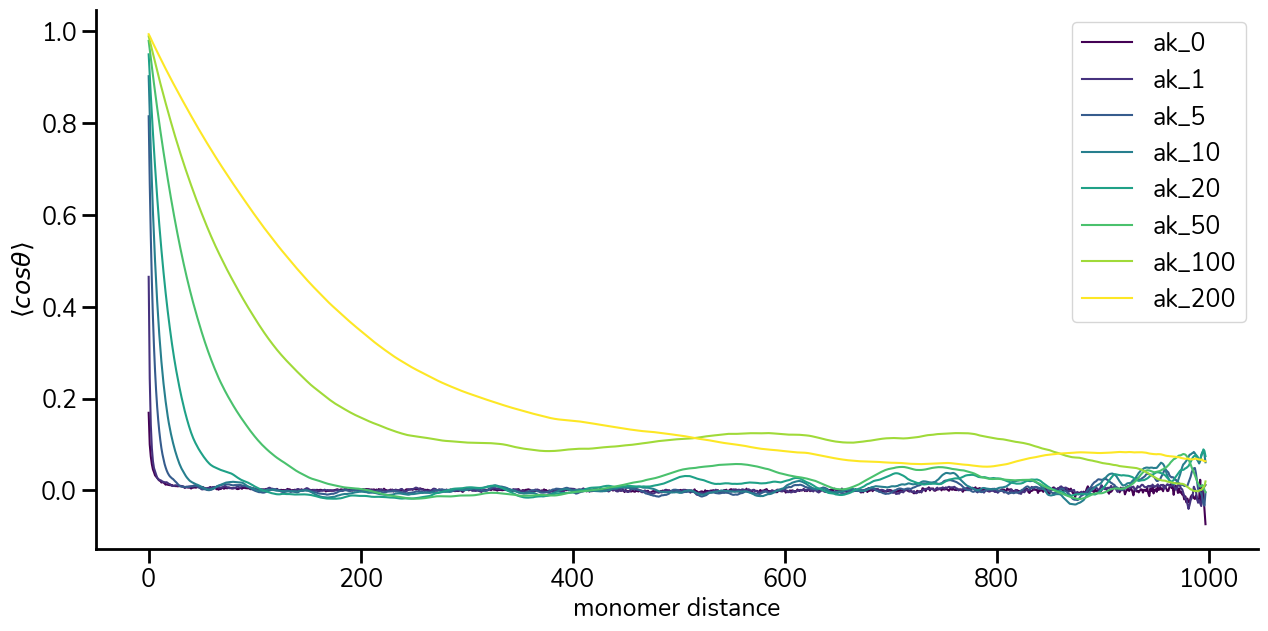

In [15]:
fig,ax = plt.subplots(figsize=(15,7))
clrs = plt.cm.viridis(np.linspace(0,1,len(anglesDict.keys())))
for ic,i in enumerate(natsorted(anglesDict.keys())):
    ax.plot(avgAvgAngles[i][:],label=i.split("_box")[0].split("repE_10_")[1],color=clrs[ic])
    # ax_new.plot(ang.AvgAngleValues(j)[:80])
ax.legend(loc="upper right")#bbox_to_anchor=(1.05, 1.04))
ax.set_xlabel("monomer distance")
ax.set_ylabel(r"$\langle cos\theta \rangle$")
# plt.savefig("angle_curve.jpg",dpi=100,bbox_inches="tight")

In [16]:
angleKs = natsorted(anglesDict.keys())
bondsLim = 100
plTable = pd.DataFrame({"angle_k":angleKs, 
                        "k":[int(i.split("_")[8]) for i in angleKs],
                       "persistence_length":[GetPersistenceLength(avgAvgAngles[i][:bondsLim],list(range(bondsLim)))[0] for i in angleKs]})
plTable

,angle_k,k,persistence_length
0,gamma_0.1_N_num_1000_repE_10_ak_0_box_len_100_...,0,0.465876
1,gamma_0.1_N_num_1000_repE_10_ak_1_box_len_100_...,1,0.834741
2,gamma_0.1_N_num_1000_repE_10_ak_5_box_len_100_...,5,4.311672
3,gamma_0.1_N_num_1000_repE_10_ak_10_box_len_100...,10,9.312479
4,gamma_0.1_N_num_1000_repE_10_ak_20_box_len_100...,20,19.232542
5,gamma_0.1_N_num_1000_repE_10_ak_50_box_len_100...,50,46.842613
6,gamma_0.1_N_num_1000_repE_10_ak_100_box_len_10...,100,99.930057
7,gamma_0.1_N_num_1000_repE_10_ak_200_box_len_10...,200,196.565992


Text(0, 0.5, 'Persistence length (um)')

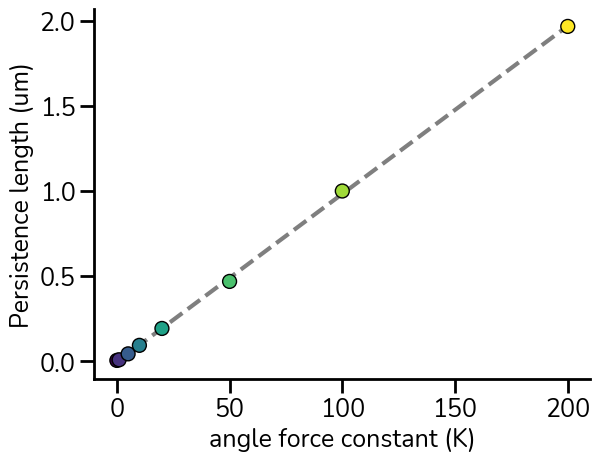

In [32]:
clrs = plt.cm.viridis(np.linspace(0,1,len(anglesDict.keys())))
m,b = np.polyfit(list(plTable["k"]),np.array(plTable["persistence_length"])*0.01, 1)
plt.scatter(list(plTable["k"]),np.array(plTable["persistence_length"])*0.01,100,marker="o",color=clrs,ec='k',zorder=10)
plt.plot(list(plTable["k"]),m*np.array(plTable["k"])+b,'--',c="k",lw=3,alpha=0.5)
plt.xlabel("angle force constant (K)")
plt.ylabel("Persistence length (um)")

In [101]:
angleKs = natsorted(anglesDict.keys())
bondsLim = 40
plTable = pd.DataFrame({"angle_k":angleKs, 
                       "persistence_length":[GetPersistenceLength(avgAvgAngles[i][:bondsLim],list(range(bondsLim)))[0] for i in angleKs]})
plTable

,angle_k,persistence_length
0,gamma_0.1_N_num_1000_repE_10_ak_0_box_len_100_...,0.465876
1,gamma_0.1_N_num_1000_repE_10_ak_1_box_len_100_...,0.834741
2,gamma_0.1_N_num_1000_repE_10_ak_5_box_len_100_...,4.311497
3,gamma_0.1_N_num_1000_repE_10_ak_10_box_len_100...,9.297576
4,gamma_0.1_N_num_1000_repE_10_ak_20_box_len_100...,18.928748
5,gamma_0.1_N_num_1000_repE_10_ak_50_box_len_100...,46.404433
6,gamma_0.1_N_num_1000_repE_10_ak_100_box_len_10...,96.039576
7,gamma_0.1_N_num_1000_repE_10_ak_200_box_len_10...,193.109499


In [102]:
pl_dict = {}
for i in natsorted(anglesDict.keys()):
    pl_dict[i] = []
    for j in np.arange(10,200,10):
        pl_dict[i].append(GetPersistenceLength(avgAvgAngles[i][:j],list(range(j)))[0])

Text(0.5, 1.0, 'Avg Persistence Length')

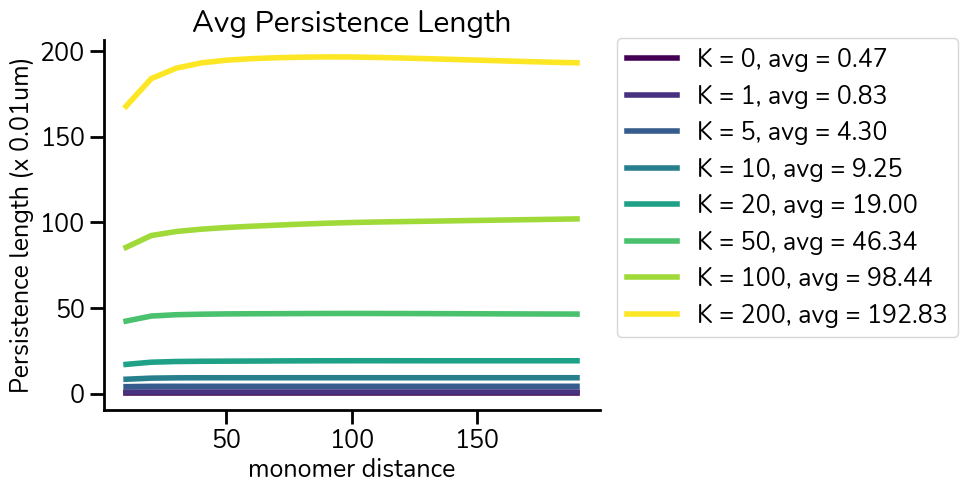

In [109]:
clrs = plt.cm.viridis(np.linspace(0,1,len(pl_dict.keys())))
for ic,i in enumerate(natsorted(pl_dict.keys())):
    plt.plot(np.arange(10,200,10),pl_dict[i],label="K = "+i.split("_box")[0].split("repE_10_")[1][3:] + f", avg = {np.mean(pl_dict[i]):.2f}",color=clrs[ic],lw=4)
plt.legend(bbox_to_anchor=(1.01, 1.04))
plt.xlabel("monomer distance")
plt.ylabel("Persistence length (x 0.01um)")
plt.title("Avg Persistence Length")

In [37]:
def fit_cos_theta_decay(n_vals, cos_theta_vals, use_oscillatory=False, plot=True):
    """
    Fit ⟨cos(θ)⟩ vs monomer distance to extract persistence length (L_p).

    Parameters:
        n_vals (np.ndarray): array of monomer distances (e.g., 0, 1, 2, ..., N)
        cos_theta_vals (np.ndarray): corresponding ⟨cos(θ)⟩ values
        use_oscillatory (bool): fit to oscillatory model if True
        plot (bool): whether to show the fit plot

    Returns:
        dict: fit parameters (e.g., L_p, A, lambda, etc.)
    """

    # Define fitting functions
    def exp_decay(n, A, L_p):
        return A * np.exp(-n / L_p)

    def damped_cosine(n, A, L_p, lam, phi):
        return A * np.exp(-n / L_p) * np.cos(2 * np.pi * n / lam + phi)

    # Select model
    if use_oscillatory:
        model = damped_cosine
        p0 = [1.0, 10.0, 50.0, 0.0]  # A, L_p, lambda, phi
        bounds = ([0, 0, 1, -np.pi], [1.5, np.inf, np.inf, np.pi])
    else:
        model = exp_decay
        p0 = [1.0, 10.0]  # A, L_p
        bounds = ([0, 0], [1.5, np.inf])

    # Fit the model
    try:
        popt, pcov = curve_fit(model, n_vals, cos_theta_vals, p0=p0, bounds=bounds)
    except RuntimeError:
        print("⚠️ Fit failed.")
        return {}

    # Generate fit curve
    n_fit = np.linspace(n_vals.min(), n_vals.max(), 500)
    fit_vals = model(n_fit, *popt)

    # Plot
    if plot:
        plt.figure(figsize=(8, 4))
        plt.plot(n_vals, cos_theta_vals, 'o', label='data')
        plt.plot(n_fit, fit_vals, '-', label='fit')
        plt.xlabel('monomer distance (n)')
        plt.ylabel(r'$\langle \cos(\theta_n) \rangle$')
        plt.title('Fit of angular correlation')
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()

    # Return fit results
    if use_oscillatory:
        return {'A': popt[0], 'L_p': popt[1], 'lambda': popt[2], 'phi': popt[3]}
    else:
        return {'A': popt[0], 'L_p': popt[1]}


Text(0, 0.5, 'angle K')

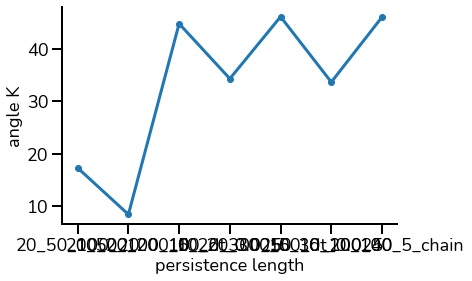

In [13]:
fig,ax = plt.subplots(figsize=(6,4))
ax.plot(plTable["angle_k"],plTable["persistence_length"],marker="o",lw=3)
ax.set_xlabel("persistence length")

ax.set_ylabel("angle K")
# plt.savefig("k_vs_pl.jpg",dpi=100,bbox_inches="tight")

In [49]:
def PlotLpFit(
    avgCosθ, 
    monomerSep,
    avgBondLen=1.0,
    ax=None
):
    """
    
    """
    if ax is None:
        ax = plt.gca()
    cosθ = lambda x,lp: np.exp(-(x * avgBondLen)/lp)
    lp,r = curve_fit(cosθ, monomerSep, avgCosθ)

    ax.plot(monomerSep,cosθ(monomerSep, lp[0]))
    ax.scatter(monomerSep, avgCosθ)
    return ax

[31.09703263] [[0.68032466]]


<AxesSubplot:>

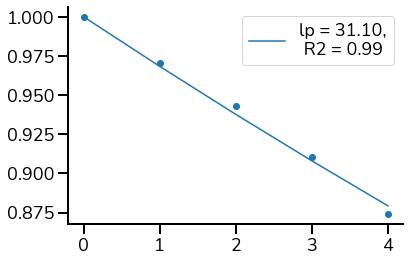

In [99]:
bondsLim = 5
ang.PlotLpFit(ang.AvgAngleValues(anglesDict["10_30_200_40"])[:bondsLim],np.array(list(range(bondsLim))))

In [48]:
[1,2,3]

[1, 2, 3]